# 02 · Cleaning, Feature Engineering & Feature Selection

1. Apply the cleaning rules found in notebook 01 (`src/loan_model/cleaning.py`) and log what each rule changed.
2. Create a **stratified 80/20 train / internal-test split** (the internal test set stands in for the unseen hold-out and is not touched until notebook 03).
3. Engineer features (`src/loan_model/features.py`).
4. **Select the minimal set of chatbot questions** using cross-validated ablation on the training split only.

In [1]:
import sys, json, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

from loan_model import config as C
from loan_model.cleaning import load_raw, clean_raw, drop_unusable_rows, target_to_int
from loan_model.features import FeatureBuilder
from loan_model.modeling import FeatureSpec, FULL_SPEC, FINAL_SPEC, build_pipeline

sns.set_theme(style="whitegrid", palette="deep")
FIG = C.FIGURES_DIR; C.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight"); plt.show()

## 1. Cleaning

In [2]:
raw = load_raw()
clean = clean_raw(raw)

# What did row-wise cleaning change?
changes = {}
for col in raw.columns:
    if col in ("ID",):
        continue
    before = raw[col].astype("string")
    after = clean[col].astype("string")
    if col in ("Age", "Loan_Amount", "LTV", "Net_salary"):
        b = pd.to_numeric(raw[col], errors="coerce"); a = clean[col]
        changes[col] = {"set_to_missing": int((b.notna() & a.isna()).sum() + (raw[col].notna() & b.isna()).sum())}
    else:
        changes[col] = {"values_rewritten": int(((before != after) & before.notna() & after.notna()).sum()),
                        "set_to_missing": int((before.notna() & after.isna()).sum())}
pd.DataFrame(changes).T.fillna(0).astype(int).query("values_rewritten > 0 or set_to_missing > 0")

,values_rewritten,set_to_missing
Age,0,1
LTV,0,65
Net_salary,0,887
Final_Tier,108400,0
Model_Description,5032,0
Model_Variant,20013,0


In [3]:
print("Descriptions still containing mojibake:", clean.Model_Description.str.contains("â", na=False).sum())
print("Example fixed description:", [d for d in clean.Model_Description.dropna().unique() if "RACE EDITION" in d])
print("Model_Variant levels after normalisation:", sorted(clean.Model_Variant.dropna().unique()))

Descriptions still containing mojibake: 0
Example fixed description: ['NTORQ 125 DISC - RACE EDITION BSVI']
Model_Variant levels after normalisation: ['110 CC', '125 CC', '125 CC DISC', '125 CC DRUM', '160 DISC', '160 DRUM', '165 CC', 'APACHE 180 CC', 'APACHE RR 310', 'APACHE RTR 310', 'EBIKE', 'RADEON', 'RAIDER', 'RONIN', 'RTR 200 CC', 'SCOOTY', 'SCOOTY PEP PLUS', 'SPORT', 'STAR CITY PLUS', 'XL 100 CC']


In [4]:
clean, row_report = drop_unusable_rows(clean)
row_report

{'rows_in': 108423,
 'dropped_no_target': 1,
 'dropped_all_features_empty': 0,
 'dropped_exact_duplicates_excl_id': 13,
 'rows_out': 108409}

In [5]:
print("Missing values after cleaning (imputed / flagged inside the model pipeline):")
m = clean.isna().sum(); m[m > 0].to_frame("missing")

Missing values after cleaning (imputed / flagged inside the model pipeline):


,missing
Qualifications,23
Employment_Type,25
Age,17
LTV,65
Resident_Type,17
Net_salary,908
Final_Tier,22
Make_Code,3
Model_Description,3
Model_Variant,3


## 2. Train / internal-test split

In [6]:
y_all = target_to_int(clean[C.TARGET])
train_df, test_df = train_test_split(clean, test_size=0.20, stratify=y_all, random_state=C.RANDOM_STATE)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
train_df.to_csv(C.PROCESSED_DIR / "train_clean.csv", index=False)
test_df.to_csv(C.PROCESSED_DIR / "test_clean.csv", index=False)
(C.PROCESSED_DIR / "cleaning_report.json").write_text(json.dumps({"row_filters": row_report, "rowwise_changes": changes}, indent=2))
pd.DataFrame({"rows": [len(train_df), len(test_df)],
              "declined_rate": [train_df.Decision.eq("DECLINED").mean(), test_df.Decision.eq("DECLINED").mean()]},
             index=["train", "internal test"]).round(4)

,rows,declined_rate
train,86727,0.0526
internal test,21682,0.0526


## 3. Engineered features

`FeatureBuilder` (fit on train only) creates:

| Feature | From | Why |
|---|---|---|
| `tier_ord` | `Final_Tier` (or looked up from pincode) | ordinal 1 (Megapolis A) … 7 (Rural) |
| `pin2`, `pin3` | Pincode prefix | postal circle / sorting district: regional risk without 14k sparse levels |
| `pincode` | full Pincode | target-encoded, tested in ablation |
| `Make_Code`, `Product_Code`, `Model_Variant` | filled from `Model_Description` when missing | one vehicle question populates all four |
| `vehicle_value` | `Loan_Amount / (LTV/100)` | price of the vehicle |
| `down_payment` | `vehicle_value − Loan_Amount` | applicant's own contribution |
| `loan_to_income` | `Loan_Amount / Net_salary` | affordability |
| `salary_missing`, `ltv_missing` | flags | missingness after cleaning may itself be informative |

Encoding (in `modeling.build_pipeline`): low-cardinality categoricals → ordinal codes used as **native categorical splits** in
HistGradientBoosting (rare levels < 20 rows grouped, unseen → own code); high-cardinality (`pin3`, `pincode`, `Model_Description`)
→ sklearn `TargetEncoder` with **internal cross-fitting** (avoids target leakage) and smoothing; numerics → passed through (the
GBM handles NaN natively).

In [7]:
fb = FeatureBuilder().fit(train_df)
feat_preview = fb.transform(train_df)
print(f"Salary cap learned on train (99.5th pct): ₹{fb.salary_cap_:,.0f}/month")
feat_preview.head()

Salary cap learned on train (99.5th pct): ₹100,000/month


,tier_ord,pin2,pin3,pincode,Make_Code,Product_Code,Model_Variant,Model_Description,Loan_Amount,LTV,...,down_payment,loan_to_income,salary_missing,ltv_missing,Age,Employment_Type,PAST_LOANS_ACTIVE,Qualifications,Resident_Type,Gender
0,7.0,21,212,212654,RAIDER,MC,RAIDER,TVS RAIDER DISC BSVI,72007.0,62.34,...,43499.897658,1.852985,0,0,38.0,AGR,PAST_LOANS_ACTIVE,UG,O,Male
1,7.0,73,733,733103,RAIDER,MC,RAIDER,TVS RAIDER DISC SSE BSVI,83656.0,64.85,...,45343.228990,2.323778,0,0,23.0,SEP,PAST_LOANS_ACTIVE,UG,O,Male
2,7.0,80,802,802213,MOPEDS,MO,XL 100 CC,TVS XL 100 HD KS BSVI,41966.0,78.74,...,11330.926594,1.311438,0,0,44.0,NREGI,NO_PAST_LOANS,HSC,O,Male
3,7.0,62,624,624613,ZEST,SC,SCOOTY,SCOOTY ZEST MATTE SERIES - BSVI,75165.0,75.27,...,24695.502192,3.416591,0,0,28.0,SAL,PAST_LOANS_ACTIVE,GRAD,O,Female
4,7.0,60,603,603201,RAIDER,MC,RAIDER,TVS RAIDER DISC SS BSVI,26605.0,22.04,...,94107.341198,1.064200,0,0,30.0,NREGI,PAST_LOANS_ACTIVE,OTHERS,O,Male


In [8]:
feat_preview.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tier_ord,86727.0,6.36,1.23,1.00,6.00,7.00,7.00,7.00
Loan_Amount,86727.0,89289.94,25537.03,17369.00,69583.00,90037.00,106751.00,286847.00
LTV,86676.0,77.74,12.55,20.00,72.18,81.34,86.04,99.60
Net_salary,85996.0,33662.76,11822.72,5000.00,25000.00,30000.00,37500.00,100000.00
vehicle_value,86676.0,115584.91,29609.83,50510.98,94063.97,116576.36,131499.30,363111.52
down_payment,86676.0,26295.29,17890.70,378.54,14004.53,21395.32,33957.60,263800.52
loan_to_income,85996.0,2.89,1.16,0.30,2.06,2.76,3.57,25.70
salary_missing,86727.0,0.01,0.09,0.00,0.00,0.00,0.00,1.00
ltv_missing,86727.0,0.00,0.02,0.00,0.00,0.00,0.00,1.00
Age,86715.0,34.41,10.74,18.00,25.00,32.00,42.00,69.00


## 4. Feature selection = choosing the chatbot questions

Each chatbot question populates a **group** of engineered features, so we select at the question level, not the column level.
`Loan amount` + `vehicle price` are always asked (they define the loan and give LTV, the strongest predictor); everything else must
earn its place.

`Gender` is **excluded up-front**: it is a protected attribute and must not drive a credit decision (fair-lending), and EDA showed
no signal anyway (5.3% vs 5.2%).

Metric: 3-fold stratified CV ROC-AUC on the **training split only** (HistGradientBoosting, default params).

In [9]:
X_tr = train_df.drop(columns=[C.ID_COL, C.TARGET]); y_tr = target_to_int(train_df[C.TARGET])
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=C.RANDOM_STATE)

QUESTIONS = {   # question -> engineered features it feeds
    "loan_amount_and_vehicle_price": ["Loan_Amount", "LTV", "vehicle_value", "down_payment", "ltv_missing"],
    "pincode":                       ["tier_ord", "pin2", "pin3", "pincode"],
    "vehicle_model":                 ["Product_Code", "Make_Code", "Model_Variant", "Model_Description"],
    "past_loans_active":             ["PAST_LOANS_ACTIVE"],
    "age":                           ["Age"],
    "employment_type":               ["Employment_Type"],
    "net_salary":                    ["Net_salary", "loan_to_income", "salary_missing"],
    "qualifications":                ["Qualifications"],
    "resident_type":                 ["Resident_Type"],
}
CANDIDATE = FULL_SPEC.drop(["Gender"])

def spec_for(questions):
    keep = set(c for q in questions for c in QUESTIONS[q])
    return CANDIDATE.drop([c for c in CANDIDATE.all if c not in keep])

_cache = {}
def cv_auc(questions):
    key = tuple(sorted(questions))
    if key not in _cache:
        s = cross_val_score(build_pipeline(spec_for(questions)), X_tr, y_tr, cv=CV, scoring="roc_auc")
        _cache[key] = (s.mean(), s.std())
    return _cache[key]

### 4.1 Drop-one ablation from the full candidate set

In [10]:
t0 = time.time()
all_q = list(QUESTIONS)
full_auc, full_sd = cv_auc(all_q)
rows = [{"question_dropped": "(none)", "cv_auc": full_auc, "delta": 0.0}]
for q in all_q[1:]:
    a, _ = cv_auc([x for x in all_q if x != q])
    rows.append({"question_dropped": q, "cv_auc": a, "delta": a - full_auc})
drop_one = pd.DataFrame(rows).sort_values("delta").round(4)
print(f"full-set CV AUC = {full_auc:.4f} ± {full_sd:.4f}   ({time.time()-t0:.0f}s)")
drop_one

full-set CV AUC = 0.7781 ± 0.0052   (66s)


,question_dropped,cv_auc,delta
1,pincode,0.7565,-0.0216
2,vehicle_model,0.7731,-0.0049
3,past_loans_active,0.7746,-0.0035
4,age,0.7753,-0.0028
5,employment_type,0.7761,-0.0020
7,qualifications,0.7778,-0.0003
0,(none),0.7781,0.0000
8,resident_type,0.7783,0.0002
6,net_salary,0.7787,0.0006


**Reading the ablation.** Pincode is by far the most valuable question after loan/price (−0.022 AUC without it), followed by
vehicle model, past loans, age and employment type. Removing **net salary, qualifications or resident type costs nothing**
(changes are within the ±0.005 fold noise, and dropping salary even *improves* AUC slightly). Self-reported income is unverified
and noisy, so the model learns nothing from it.

Negative delta = AUC lost when that question is removed. Changes within roughly ±0.001–0.002 are inside fold-to-fold noise
(see the ± above).

### 4.2 Forward selection — accuracy vs number of questions

In [11]:
t0 = time.time()
selected = ["loan_amount_and_vehicle_price"]
path = [{"n_questions": 2, "added": "loan_amount + vehicle_price", "cv_auc": cv_auc(selected)[0]}]
remaining = [q for q in all_q if q not in selected]
while remaining:
    scores = {q: cv_auc(selected + [q])[0] for q in remaining}
    best = max(scores, key=scores.get)
    selected.append(best); remaining.remove(best)
    path.append({"n_questions": len(selected) + 1, "added": best, "cv_auc": scores[best]})
fwd = pd.DataFrame(path); fwd["gain"] = fwd.cv_auc.diff().round(4)
print(f"{time.time()-t0:.0f}s"); fwd.round(4)

257s


,n_questions,added,cv_auc,gain
0,2,loan_amount + vehicle_price,0.7345,NaN
1,3,pincode,0.7642,0.0298
2,4,vehicle_model,0.7707,0.0065
3,5,past_loans_active,0.7736,0.0029
4,6,age,0.7760,0.0024
5,7,employment_type,0.7780,0.0020
6,8,resident_type,0.7784,0.0004
7,9,qualifications,0.7787,0.0003
8,10,net_salary,0.7781,-0.0006


**Diminishing returns.** Loan + price alone give AUC 0.735; adding pincode jumps to 0.764; vehicle model, past loans, age and
employment each add +0.002–0.007. After 7 questions the next three add < +0.0005 each and are noise. We stop at **7 questions**.

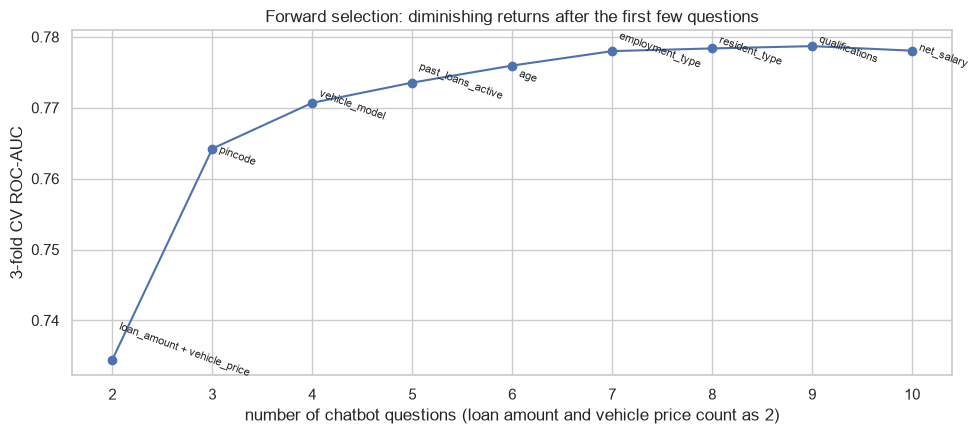

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(fwd.n_questions, fwd.cv_auc, marker="o")
for _, r in fwd.iterrows():
    ax.annotate(r.added, (r.n_questions, r.cv_auc), textcoords="offset points", xytext=(4, -12), fontsize=8, rotation=-20)
ax.set_xlabel("number of chatbot questions (loan amount and vehicle price count as 2)"); ax.set_ylabel("3-fold CV ROC-AUC")
ax.set_title("Forward selection: diminishing returns after the first few questions")
savefig("11_forward_selection")

### 4.3 Location granularity: full pincode vs prefixes

In [13]:
base_q = ["loan_amount_and_vehicle_price", "pincode", "vehicle_model", "past_loans_active", "age", "employment_type"]
variants = {
    "tier only": ["pincode", "pin2", "pin3"],
    "tier + pin2": ["pincode", "pin3"],
    "tier + pin2 + pin3": ["pincode"],
    "tier + pin2 + pin3 + full pincode": [],
}
res = {}
for name, drop in variants.items():
    s = cross_val_score(build_pipeline(spec_for(base_q).drop(drop)), X_tr, y_tr, cv=CV, scoring="roc_auc")
    res[name] = s.mean()
pd.Series(res, name="cv_auc").round(4).to_frame()

,cv_auc
tier only,0.7561
tier + pin2,0.7750
tier + pin2 + pin3,0.7783
tier + pin2 + pin3 + full pincode,0.7780


**Location granularity.** Tier alone loses most of the geographic signal; the 2- and 3-digit pincode prefixes recover it. The full
6-digit pincode adds nothing on top (most of its 14k levels have only a handful of rows), so the model uses tier + `pin2` + `pin3`.
The chatbot still asks for the 6-digit pincode once, and every location feature is derived from it.

### 4.4 Final question set

In [14]:
final_q = ["loan_amount_and_vehicle_price", "pincode", "vehicle_model", "past_loans_active", "age", "employment_type"]
cmp = pd.DataFrame({
    "spec": ["all candidate questions (9 groups, 10 questions)", "FINAL_SPEC (6 groups, 7 questions)"],
    "cv_auc": [cv_auc(all_q)[0],
               cross_val_score(build_pipeline(FINAL_SPEC), X_tr, y_tr, cv=CV, scoring="roc_auc").mean()],
}).round(4)
print("FINAL_SPEC features:", FINAL_SPEC.all)
cmp

FINAL_SPEC features: ['Age', 'Loan_Amount', 'LTV', 'vehicle_value', 'down_payment', 'tier_ord', 'ltv_missing', 'Employment_Type', 'PAST_LOANS_ACTIVE', 'Product_Code', 'Make_Code', 'Model_Variant', 'pin2', 'pin3', 'Model_Description']


,spec,cv_auc
0,"all candidate questions (9 groups, 10 questions)",0.7781
1,"FINAL_SPEC (6 groups, 7 questions)",0.7783


### Selected fields and why

| # | Chatbot question | Model fields populated | Why kept |
|---|---|---|---|
| 1 | Pincode | `tier_ord`, `pin2`, `pin3` (Final_Tier looked up) | Biggest gain after LTV (+0.030 AUC) |
| 2 | Which vehicle model? (picked from a list) | `Model_Description` → `Make_Code`, `Product_Code`, `Model_Variant` | +0.0065; one pick fills four fields |
| 3 | Vehicle on-road price | `vehicle_value`, `LTV`, `down_payment` | LTV is the strongest single predictor |
| 4 | Loan amount required | `Loan_Amount`, `LTV` | Defines the application |
| 5 | Any active loans currently? | `PAST_LOANS_ACTIVE` | +0.003 |
| 6 | Age / date of birth | `Age` | +0.002, also the 18–60 policy check |
| 7 | Employment type | `Employment_Type` | +0.002 |

**Dropped:** Net_salary (no signal, poor quality), Qualifications, Resident_Type (no signal), full Pincode (redundant with its prefixes),
Gender (protected attribute, never used).

The 7-question model matches the 10-question model (0.7783 vs 0.7781 CV AUC) with 30% fewer questions. This is `FINAL_SPEC` in
`src/loan_model/modeling.py`, used in notebook 03.